# Example of Assignment 2

The idea behind assignment 2 is to use develop two ML models which recognizes emotions from images (sad face, happy, surprised, etc.). In order to achieve this, there are a few technical challenges that should be tackle, such as data imbalance, choosing the right features for the datastet, normalization strategies, etc. 

This notebook provides a basic example of a pipeline that a random forest with landmarks and evaluates the model to compute the confusion matrix, (balanced)accuracy and F1 macro.

### Loading and perform feature extraction on the dataset

In [1]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

Now we compute the class weights for the training set

In [2]:
csv_file = './data/fer2013_train.csv'
model_file = "./models/rf_fer_model_landmarks.pkl"

### Loading the data

In [3]:
###############################
# Computing class weights
##############################
from sklearn.utils.class_weight import compute_class_weight

trai_df = pd.read_csv(csv_file)

# Computing class weights for unbalanced dataset
labelsTrain = trai_df['emotion'].values
cw = compute_class_weight(
    class_weight="balanced", classes=np.unique(labelsTrain), y=labelsTrain)
#class_weights = {0:cw[0],1:cw[1],2:cw[2], 3:cw[3], 4:cw[4], 5:cw[5], 6:cw[6]}

### This is an example of a feature extraction pipeline
For this simple baseline model, we use a simple feature extraction pipeline with landmarks

In [4]:
import dlib 

# Importing dlib's landmark detector
# Dlib landmarks from: 
#   https://github.com/davisking/dlib-models/blob/master/shape_predictor_68_face_landmarks.dat.bz2
landmDet = dlib.shape_predictor("faceAndLandmarkModels/shape_predictor_68_face_landmarks_GTX.dat")

# Initialize scaler and classifier
scaler = StandardScaler()

# Track if scaler is fitted
scaler_fitted = False

def extractLandmarksFER(images):
    face_rects = dlib.rectangle(left=1, top=1, right=47, bottom=47)
    x1 = face_rects.left() 
    y1 = face_rects.top() 
    x2 = face_rects.right() 
    y2 = face_rects.bottom()

    landm = []
    for img in images:
        la = landmDet(img.astype(np.uint8), face_rects)

        # This works better if the standard scaler is not usec
        la2 = np.asarray( np.matrix([
            [
                (p.x-0.5*(x2-x1))/(x2-x1), (p.y-0.5*(y2-y1))/(y2-y1)
            ] for p in la.parts()])).astype(np.float32)
        la2 -= np.mean(la2, axis=0, keepdims=True)
        la2 /= np.max(np.abs(la2), axis=0, keepdims=True)

        landm.append(la2.flatten())
    feats = np.stack(landm)
    return(feats)

# Loading the images
images = np.array(
        [np.fromstring(pixels, sep=' ').reshape(48, 48) for pixels in trai_df['pixels']])
feats = extractLandmarksFER(images)

images = None

### Evaluating the results

In [5]:
from sklearn.ensemble import RandomForestClassifier
import joblib


rf = RandomForestClassifier(
    n_estimators=300,       # Number of trees
    max_depth=11,           # Allow trees to grow fully
    max_features='sqrt',   # Use sqrt(features) for splitting
    random_state=42,
    n_jobs=-1,             # Use all available CPU cores 
    #class_weight= "balanced", #class_weights,
    criterion="entropy",
)


rf.fit(feats, trai_df['emotion'].values)

joblib.dump(rf, model_file)
print(f"Model saved to {model_file}")

Model saved to ./models/rf_fer_model_landmarks.pkl


Finally, now that we have the trained models, we perfom the performance measurements in the validation set

Accuracy: 0.45
Balanced accuracy: 0.38
Macro F1: 0.38


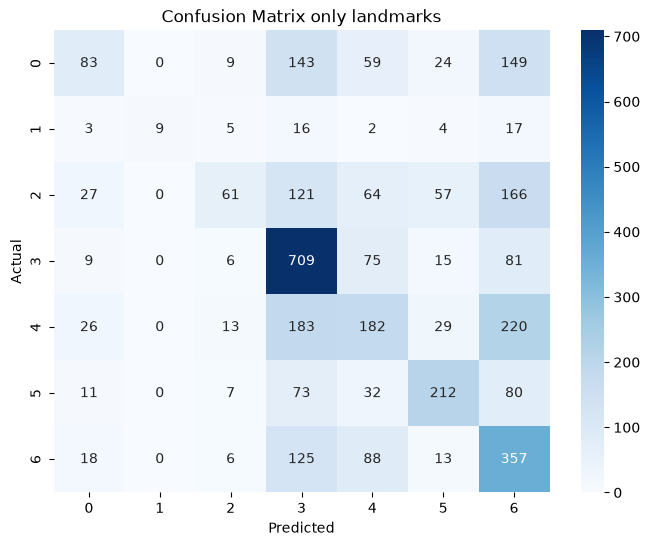

In [6]:
def preprocessingFer(dataFrame):
    # Convert pixel strings to 48x48 images
    images = np.array(
        [np.fromstring(pixels, sep=' ').reshape(48, 48) for pixels in dataFrame['pixels']])
    X =  extractLandmarksFER(images)
    y = dataFrame['emotion'].values
    return([X,y])


# Predict and evaluate
valid = pd.read_csv('./data/fer2013_validation.csv')
X_valid, y_valid = preprocessingFer(valid)

y_pred = rf.predict(X_valid)
accuracy = accuracy_score(y_valid, y_pred)
conf_matrix = confusion_matrix(y_valid, y_pred)

from sklearn.metrics import balanced_accuracy_score, f1_score
baccuracy = balanced_accuracy_score(y_valid, y_pred)
macro_f1 = f1_score(y_valid, y_pred, average='macro')


# Print results
print(f"Accuracy: {accuracy:.2f}")
print(f"Balanced accuracy: {baccuracy:.2f}")
print(f"Macro F1: {macro_f1:.2f}")


plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix only landmarks")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


## Our FER2013 Experiments

The sections below extend the provided Random Forest and landmark example. We compare LR, SVM, and RF with landmarks, HOG, and PCA features. We use validation results to choose the model settings, then evaluate the selected model on PrivateTest.

Accuracy is the share of correct predictions. Balanced accuracy averages recall across classes. Macro F1 gives each class the same weight. These scores help us compare models when class sizes differ.


### Logistic Regression with Landmarks

Accuracy: 0.4319
Balanced accuracy: 0.3572
Macro F1: 0.3513


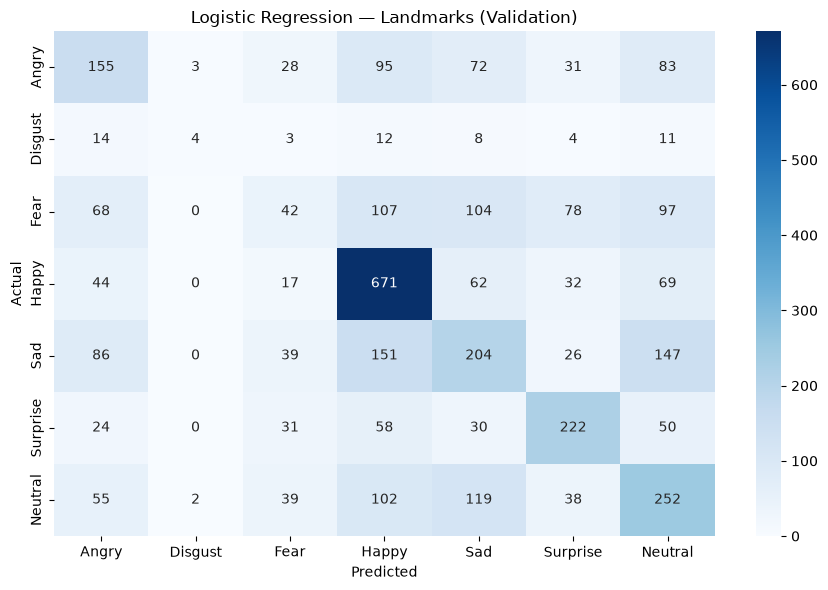

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

# StandardScaler is fitted only on the training data
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42))

# Train using the same landmark features as Random Forest
lr.fit(feats, trai_df["emotion"].values)

# Evaluate on the validation set
y_pred_lr = lr.predict(X_valid)

print(f"Accuracy: {accuracy_score(y_valid, y_pred_lr):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_valid, y_pred_lr):.4f}")
print(f"Macro F1: {f1_score(y_valid, y_pred_lr, average='macro'):.4f}")

# Save both the scaler and classifier
joblib.dump(lr, "./models/lr_fer_model_landmarks.pkl")

# Plot confusion matrix
emotion_names = ["Angry", "Disgust", "Fear", "Happy", "Sad", "Surprise", "Neutral"]

cm_lr = confusion_matrix(y_valid, y_pred_lr, labels=range(7))

plt.figure(figsize=(9, 6))
sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues", xticklabels=emotion_names, yticklabels=emotion_names)
plt.title("Logistic Regression — Landmarks (Validation)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

### SVM with Landmarks

Accuracy: 0.4648
Balanced accuracy: 0.3737
Macro F1: 0.3670


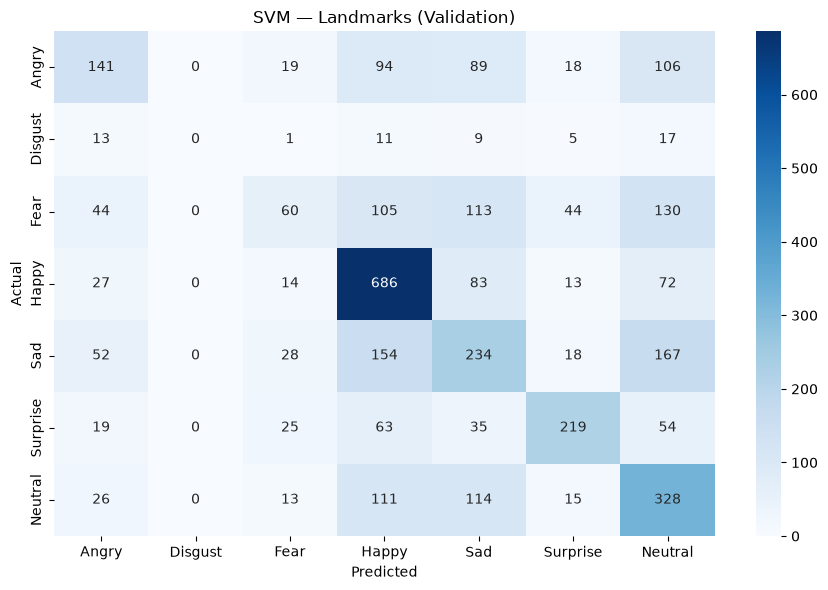

In [ ]:
from sklearn.svm import SVC

# Scale features and train an SVM
svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale"))

svm.fit(feats, trai_df["emotion"].values)

# Evaluate on the same validation set
y_pred_svm = svm.predict(X_valid)

print(f"Accuracy: {accuracy_score(y_valid, y_pred_svm):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_valid, y_pred_svm):.4f}")
print(f"Macro F1: {f1_score(y_valid, y_pred_svm, average='macro'):.4f}")

# Save the scaler and classifier together
joblib.dump(svm, "./models/svm_fer_model_landmarks.pkl")

# Plot confusion matrix
cm_svm = confusion_matrix(y_valid, y_pred_svm, labels=range(7))

plt.figure(figsize=(9, 6))
sns.heatmap(cm_svm, annot=True, fmt="d", cmap="Blues", xticklabels=emotion_names, yticklabels=emotion_names)
plt.title("SVM — Landmarks (Validation)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

### Landmark Results

SVM has the highest landmark accuracy (46.48%). However, RF has higher balanced accuracy (0.3759) and macro F1 (0.3793) than SVM. This shows why accuracy alone is not enough when class sizes differ.

## 3. HOG Features

HOG describes the direction of local image edges. We use 9 edge directions, 8 × 8 pixel cells, and 2 × 2 cell blocks. This gives 900 features per image. We use the same settings for training and validation and compare the same three models.

In [ ]:
from skimage.feature import hog

# Extract HOG features from every image in the dataframe
def extract_hog_features(data_frame):
    features = []

    for pixels in data_frame["pixels"]:
        # Convert the pixel string into a 48x48 image
        image = np.fromstring(pixels, sep=" ", dtype=np.float32).reshape(48, 48)

        # Compute the HOG descriptor for this image
        feature = hog(image, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), block_norm="L2-Hys", feature_vector=True)
        features.append(feature)

    return np.asarray(features, dtype=np.float32)

# Build HOG features for the training and validation sets
X_train_hog = extract_hog_features(trai_df)
X_valid_hog = extract_hog_features(valid)

print("Training HOG:", X_train_hog.shape)
print("Validation HOG:", X_valid_hog.shape)

Training HOG: (28709, 900)
Validation HOG: (3589, 900)


### Logistic Regression with HOG

HOG + Logistic Regression
Accuracy: 0.4347
Balanced accuracy: 0.3948
Macro F1: 0.3937


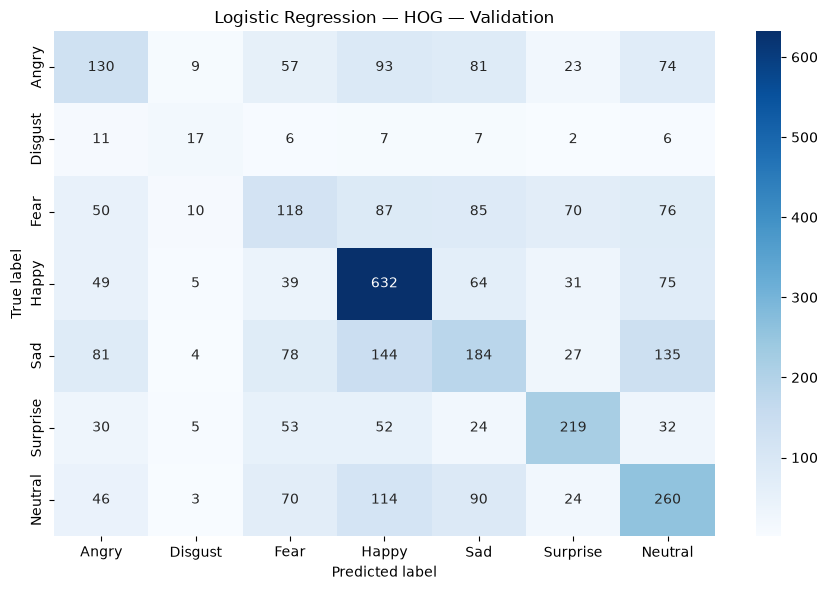

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix
import joblib

# Scale the HOG features and train a logistic regression
lr_hog = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42))

lr_hog.fit(X_train_hog, trai_df["emotion"].values)
y_pred_lr_hog = lr_hog.predict(X_valid_hog)

# Evaluate on the validation set
print("HOG + Logistic Regression")
print(f"Accuracy: {accuracy_score(y_valid, y_pred_lr_hog):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_valid, y_pred_lr_hog):.4f}")
print(f"Macro F1: {f1_score(y_valid, y_pred_lr_hog, average='macro'):.4f}")

# Save the scaler and classifier together
joblib.dump(lr_hog, "./models/lr_fer_model_hog.pkl")

# Plot confusion matrix
emotion_names = ["Angry", "Disgust", "Fear", "Happy", "Sad", "Surprise", "Neutral"]

cm = confusion_matrix(y_valid, y_pred_lr_hog, labels=range(7))

plt.figure(figsize=(9, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=emotion_names, yticklabels=emotion_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Logistic Regression — HOG — Validation")
plt.tight_layout()
plt.show()

### Random Forest with HOG

HOG + Random Forest
Accuracy: 0.4528
Balanced accuracy: 0.3758
Macro F1: 0.3885


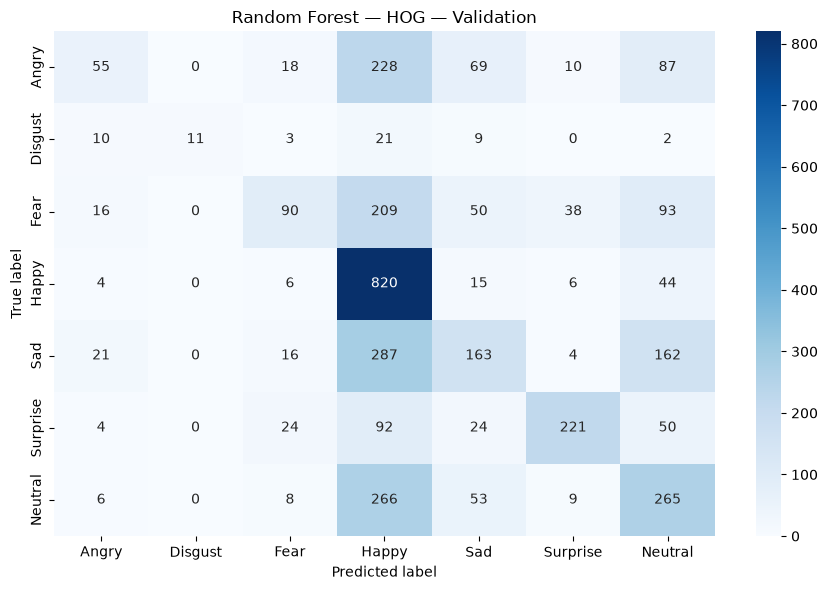

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Train a random forest on the HOG features
rf_hog = RandomForestClassifier(n_estimators=300, max_depth=11, max_features="sqrt", random_state=42, n_jobs=-1, criterion="entropy")

rf_hog.fit(X_train_hog, trai_df["emotion"].values)
y_pred_rf_hog = rf_hog.predict(X_valid_hog)

# Evaluate on the validation set
print("HOG + Random Forest")
print(f"Accuracy: {accuracy_score(y_valid, y_pred_rf_hog):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_valid, y_pred_rf_hog):.4f}")
print(f"Macro F1: {f1_score(y_valid, y_pred_rf_hog, average='macro'):.4f}")

# Save the trained model
joblib.dump(rf_hog, "./models/rf_fer_model_hog.pkl")

# Plot confusion matrix
cm = confusion_matrix(y_valid, y_pred_rf_hog, labels=range(7))

plt.figure(figsize=(9, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=emotion_names, yticklabels=emotion_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Random Forest — HOG — Validation")
plt.tight_layout()
plt.show()

### SVM with HOG

Training HOG + SVM...
HOG + SVM
Accuracy: 0.5419
Balanced accuracy: 0.4819
Macro F1: 0.5047


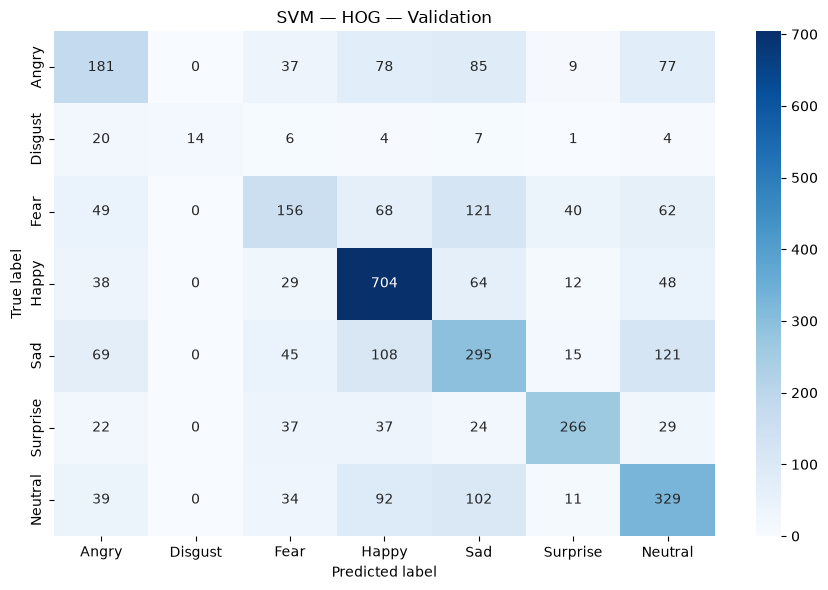

In [ ]:
from sklearn.svm import SVC

# Scale the HOG features and train an SVM
svm_hog = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale"))

print("Training HOG + SVM...", flush=True)
svm_hog.fit(X_train_hog, trai_df["emotion"].values)
y_pred_svm_hog = svm_hog.predict(X_valid_hog)

# Evaluate on the validation set
print("HOG + SVM")
print(f"Accuracy: {accuracy_score(y_valid, y_pred_svm_hog):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_valid, y_pred_svm_hog):.4f}")
print(f"Macro F1: {f1_score(y_valid, y_pred_svm_hog, average='macro'):.4f}")

# Save the scaler and classifier together
joblib.dump(svm_hog, "./models/svm_fer_model_hog.pkl")

# Plot confusion matrix
cm = confusion_matrix(y_valid, y_pred_svm_hog, labels=range(7))

plt.figure(figsize=(9, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=emotion_names, yticklabels=emotion_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("SVM — HOG — Validation")
plt.tight_layout()
plt.show()

### HOG Results

HOG + SVM reaches 54.19% accuracy, 0.4819 balanced accuracy, and 0.5047 macro F1. It has the highest scores among the three HOG models. Its accuracy is 7.71 percentage points higher than landmark SVM. HOG LR and RF improve less in accuracy compared with their landmark versions.

## 4. PCA Features from Raw Pixels

We scale pixel values to the range 0–1 and apply PCA to the 2,304 raw pixel values per image. We keep 150 components as an initial setting. PCA is fitted only on the training set and then used to transform the validation set.

The 150 components keep 92.31% of the training pixel variance. This is not classification accuracy. PCA keeps large changes in the pixels, which may not be the changes that best separate expressions. We apply PCA to raw pixels, rather than to HOG or landmarks.

In [ ]:
from sklearn.decomposition import PCA

# Convert each pixel string into a flat vector and scale values to [0, 1]
def extract_pixel_features(data_frame):
    return np.stack([np.fromstring(pixels, sep=" ", dtype=np.float32) for pixels in data_frame["pixels"]]) / 255.0

# Build raw pixel features for the training and validation sets
X_train_pixels = extract_pixel_features(trai_df)
X_valid_pixels = extract_pixel_features(valid)

# Reduce the 2304 pixel dimensions to 150 principal components
pca = PCA(n_components=150, svd_solver="randomized", random_state=42)

# Fit PCA only on the training set
X_train_pca = pca.fit_transform(X_train_pixels)
X_valid_pca = pca.transform(X_valid_pixels)

print("Training PCA:", X_train_pca.shape)
print("Validation PCA:", X_valid_pca.shape)
print("Explained variance:", f"{pca.explained_variance_ratio_.sum():.2%}")

# Save the fitted PCA for later use
joblib.dump(pca, "./models/pca_fer_pixels.pkl")

Training PCA: (28709, 150)
Validation PCA: (3589, 150)
Explained variance: 92.31%


['./models/pca_fer_pixels.pkl']

### Logistic Regression with PCA Features

PCA + Logistic Regression
Accuracy: 0.3870
Balanced accuracy: 0.3040
Macro F1: 0.2919


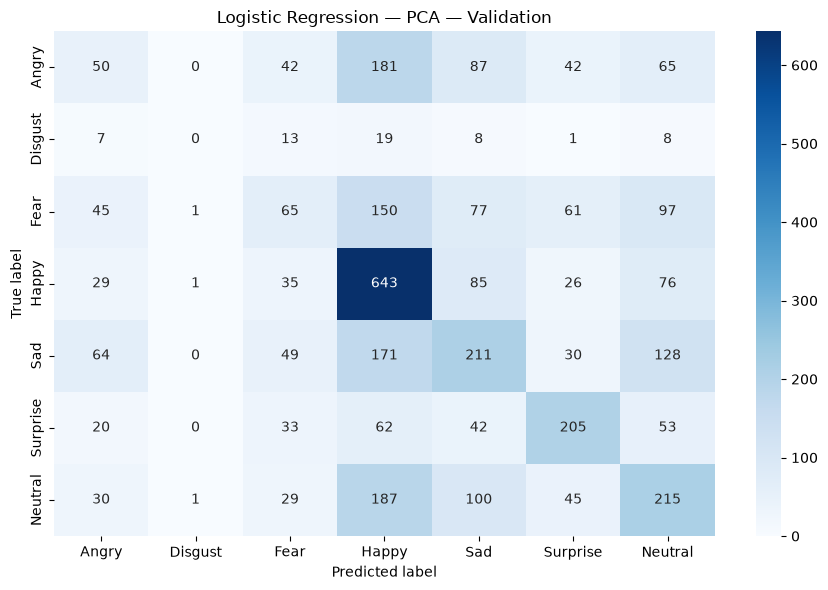

In [ ]:
# Scale the PCA features and train a logistic regression
lr_pca = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=42))

lr_pca.fit(X_train_pca, trai_df["emotion"].values)
y_pred_lr_pca = lr_pca.predict(X_valid_pca)

# Evaluate on the validation set
print("PCA + Logistic Regression")
print(f"Accuracy: {accuracy_score(y_valid, y_pred_lr_pca):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_valid, y_pred_lr_pca):.4f}")
print(f"Macro F1: {f1_score(y_valid, y_pred_lr_pca, average='macro'):.4f}")

# Save the scaler and classifier together
joblib.dump(lr_pca, "./models/lr_fer_model_pca.pkl")

# Plot confusion matrix
cm = confusion_matrix(y_valid, y_pred_lr_pca, labels=range(7))

plt.figure(figsize=(9, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=emotion_names, yticklabels=emotion_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Logistic Regression — PCA — Validation")
plt.tight_layout()
plt.show()

### Random Forest with PCA Features

PCA + Random Forest
Accuracy: 0.3731
Balanced accuracy: 0.2907
Macro F1: 0.2892


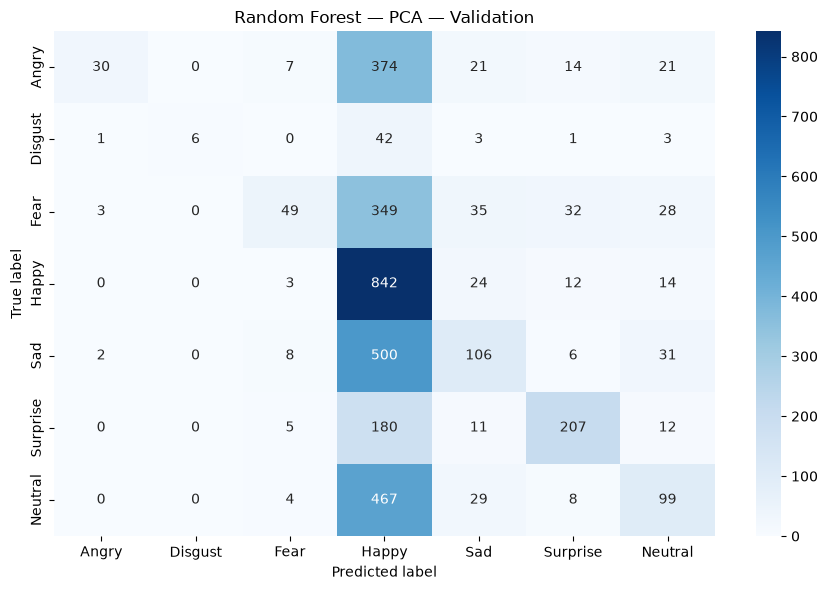

In [ ]:
rf_pca = RandomForestClassifier(
    n_estimators=300,
    max_depth=11,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1,
    criterion="entropy"
)

rf_pca.fit(X_train_pca, trai_df["emotion"].values)
y_pred_rf_pca = rf_pca.predict(X_valid_pca)

# Evaluate on the validation set
print("PCA + Random Forest")
print(f"Accuracy: {accuracy_score(y_valid, y_pred_rf_pca):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_valid, y_pred_rf_pca):.4f}")
print(f"Macro F1: {f1_score(y_valid, y_pred_rf_pca, average='macro'):.4f}")

# Save the trained model
joblib.dump(rf_pca, "./models/rf_fer_model_pca.pkl")

# Plot confusion matrix
cm = confusion_matrix(y_valid, y_pred_rf_pca, labels=range(7))

plt.figure(figsize=(9, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=emotion_names, yticklabels=emotion_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Random Forest — PCA — Validation")
plt.tight_layout()
plt.show()

### SVM with PCA Features

Training PCA + SVM...
PCA + SVM
Accuracy: 0.4670
Balanced accuracy: 0.4020
Macro F1: 0.4215


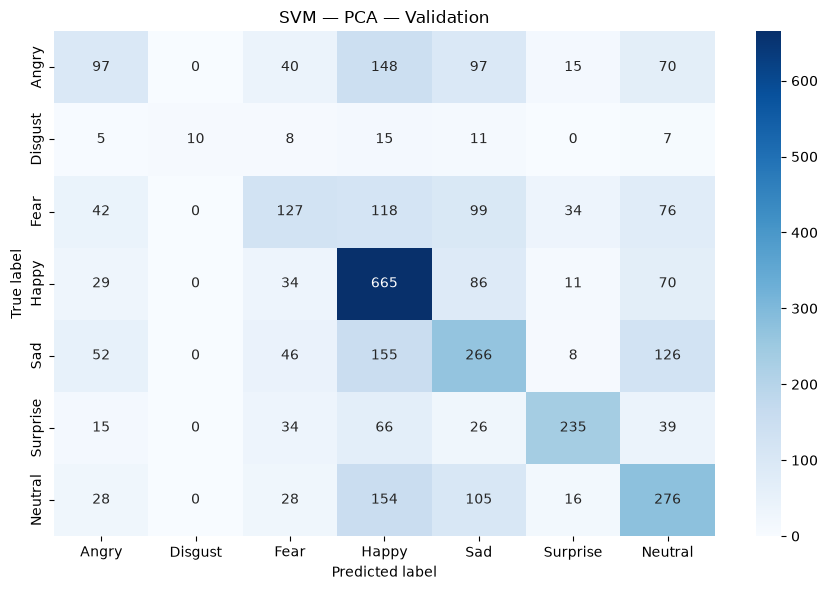

In [ ]:
# Scale the PCA features and train an SVM
svm_pca = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale"))

print("Training PCA + SVM...", flush=True)
svm_pca.fit(X_train_pca, trai_df["emotion"].values)
y_pred_svm_pca = svm_pca.predict(X_valid_pca)

# Evaluate on the validation set
print("PCA + SVM")
print(f"Accuracy: {accuracy_score(y_valid, y_pred_svm_pca):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_valid, y_pred_svm_pca):.4f}")
print(f"Macro F1: {f1_score(y_valid, y_pred_svm_pca, average='macro'):.4f}")

# Save the scaler and classifier together
joblib.dump(svm_pca, "./models/svm_fer_model_pca.pkl")

# Plot confusion matrix
cm = confusion_matrix(y_valid, y_pred_svm_pca, labels=range(7))

plt.figure(figsize=(9, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=emotion_names, yticklabels=emotion_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("SVM — PCA — Validation")
plt.tight_layout()
plt.show()

### PCA Results

PCA features give lower accuracy than HOG for all three models. Compared with landmarks, PCA gives lower accuracy for LR and RF, but slightly higher accuracy for SVM (46.48% to 46.70%). PCA SVM also has higher balanced accuracy and macro F1 than landmark SVM.

Keeping 92.31% of pixel variance does not mean keeping all the information needed to recognize expressions. Also, this is a comparison of feature types, not a direct test of raw pixels before and after PCA.

## 5. Baseline Validation Comparison

In [ ]:
model_results = [
    ("Landmarks", "LR", lr, X_valid),
    ("Landmarks", "RF", rf, X_valid),
    ("Landmarks", "SVM", svm, X_valid),
    ("HOG", "LR", lr_hog, X_valid_hog),
    ("HOG", "RF", rf_hog, X_valid_hog),
    ("HOG", "SVM", svm_hog, X_valid_hog),
    ("PCA", "LR", lr_pca, X_valid_pca),
    ("PCA", "RF", rf_pca, X_valid_pca),
    ("PCA", "SVM", svm_pca, X_valid_pca),
]

rows = []
# Compute the validation metrics for every model
for feature, classifier, model, X in model_results:
    predictions = model.predict(X)
    rows.append({
        "Features": feature,
        "Classifier": classifier,
        "Accuracy": accuracy_score(y_valid, predictions),
        "Balanced accuracy": balanced_accuracy_score(
            y_valid, predictions
        ),
        "Macro F1": f1_score(
            y_valid, predictions, average="macro"
        )
    })

results_df = pd.DataFrame(rows)
display(results_df.round(4))

,Features,Classifier,Accuracy,Balanced accuracy,Macro F1
0,Landmarks,LR,0.4319,0.3572,0.3513
1,Landmarks,RF,0.4494,0.3759,0.3793
2,Landmarks,SVM,0.4648,0.3737,0.3670
3,HOG,LR,0.4347,0.3948,0.3937
4,HOG,RF,0.4528,0.3758,0.3885
5,HOG,SVM,0.5419,0.4819,0.5047
6,PCA,LR,0.3870,0.3040,0.2919
7,PCA,RF,0.3731,0.2907,0.2892
8,PCA,SVM,0.4670,0.4020,0.4215


### Baseline Summary

We have compared all nine combinations on the same validation set. HOG + SVM is the best baseline on accuracy, balanced accuracy, and macro F1. We use it as the starting point for the next experiments. PrivateTest has not been used for these choices.

### Tune the HOG SVM

HOG + SVM gives the highest baseline macro F1, so we test `C` values of 0.1, 1, and 10. These values cover different strengths of regularization while limiting training time. A smaller `C` allows more training errors; a larger `C` penalizes them more strongly.

We keep `gamma="scale"` and choose `C` using validation macro F1. The existing `C=1` model is reused.

In [ ]:
# Reuse the existing C=1 baseline
svm_hog_candidates = {1.0: svm_hog}
tuning_rows = []

# Try three values of C and compare them on the validation set
for c in [0.1, 1.0, 10.0]:
    print(f"Evaluating C={c}...", flush=True)

    # Only train a new model if this C has not been trained yet
    if c not in svm_hog_candidates:
        model = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=c, gamma="scale"))
        model.fit(X_train_hog, trai_df["emotion"].values)
        svm_hog_candidates[c] = model

    predictions = svm_hog_candidates[c].predict(X_valid_hog)

    tuning_rows.append({
        "C": c,
        "Accuracy": accuracy_score(y_valid, predictions),
        "Balanced accuracy": balanced_accuracy_score(y_valid, predictions),
        "Macro F1": f1_score(y_valid, predictions, average="macro")
    })

    print(f"Macro F1: {tuning_rows[-1]['Macro F1']:.4f}", flush=True)

# Show the tuning results in one table
svm_tuning_df = pd.DataFrame(tuning_rows)
display(svm_tuning_df.round(4))

# Pick the C with the highest macro F1
best_index = svm_tuning_df["Macro F1"].idxmax()
best_c = float(svm_tuning_df.loc[best_index, "C"])
best_svm_hog = svm_hog_candidates[best_c]

joblib.dump(best_svm_hog, "./models/svm_fer_model_hog_tuned.pkl")

print("Best C:", best_c)

Evaluating C=0.1...
Macro F1: 0.3523
Evaluating C=1.0...
Macro F1: 0.5047
Evaluating C=10.0...
Macro F1: 0.5624


,C,Accuracy,Balanced accuracy,Macro F1
0,0.1,0.4547,0.3552,0.3523
1,1.0,0.5419,0.4819,0.5047
2,10.0,0.5698,0.5405,0.5624


Best C: 10.0


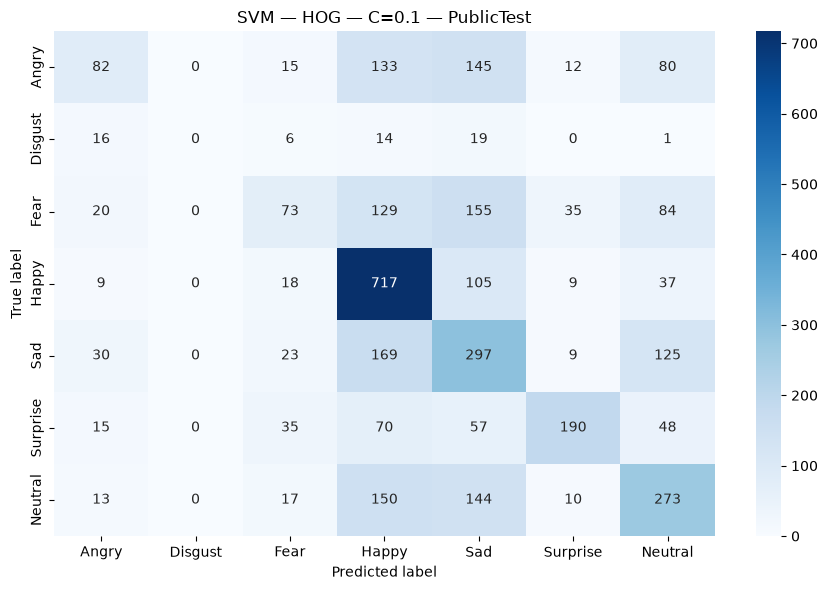

In [28]:
y_pred_c01 = svm_hog_candidates[0.1].predict(X_valid_hog)
cm_c01 = confusion_matrix(y_valid, y_pred_c01, labels=range(7))

plt.figure(figsize=(9, 6))
sns.heatmap(cm_c01, annot=True, fmt="d", cmap="Blues",
            xticklabels=emotion_names, yticklabels=emotion_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("SVM — HOG — C=0.1 — PublicTest")
plt.tight_layout()
plt.savefig("fer_svm_hog_c0.1_val.png", dpi=300, bbox_inches="tight")
plt.show()

### C Search Results

Among the three values tested, `C=10` gives the best validation scores: 56.98% accuracy, 0.5405 balanced accuracy, and 0.5624 macro F1. Compared with `C=1`, accuracy rises by 2.79 percentage points and macro F1 rises by 0.0577. This is the best value in our small search, not proof that it is the best possible value.

### Confusion Matrix for the Selected HOG SVM

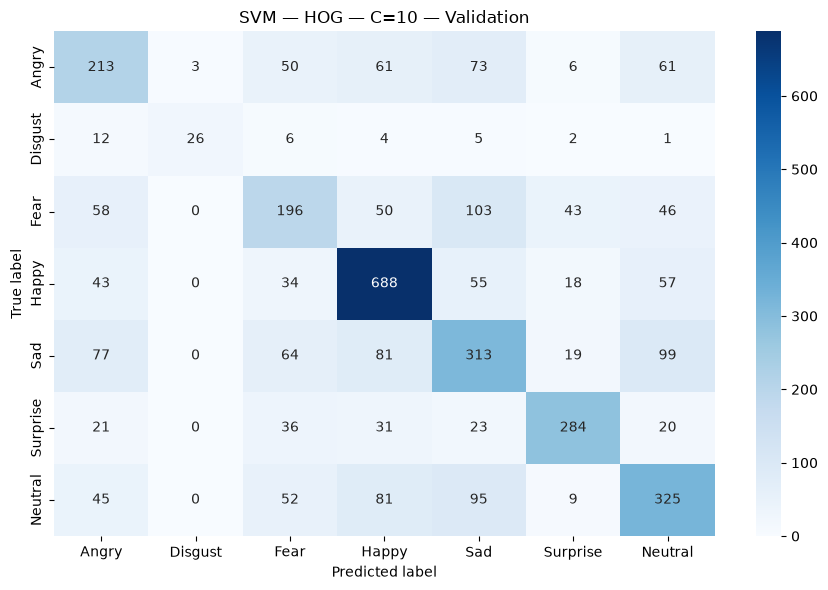

In [ ]:
# Predict with the tuned SVM on the validation set
y_pred_svm_hog_tuned = best_svm_hog.predict(X_valid_hog)
cm = confusion_matrix(y_valid, y_pred_svm_hog_tuned, labels=range(7))

plt.figure(figsize=(9, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=emotion_names, yticklabels=emotion_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title(f"SVM — HOG — C={best_c:g} — Validation")
plt.tight_layout()
plt.show()

## 6. Improvement 1: Balanced Class Weights

Happy has many more training images than Disgust. We test `class_weight="balanced"` to give more weight to errors on smaller classes. We keep HOG, `C=10`, and `gamma="scale"` for this experiment and compare it with the SVM without class weights.

In [ ]:
# Same tuned SVM, but with class weights to handle the imbalanced emotion classes
svm_hog_balanced = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=best_c, gamma="scale", class_weight="balanced", cache_size=512))

print("Training balanced HOG + SVM...", flush=True)
svm_hog_balanced.fit(X_train_hog, trai_df["emotion"].values)

y_pred_hog_balanced = svm_hog_balanced.predict(X_valid_hog)

# Compare the tuned SVM with and without balanced class weights
balanced_comparison = pd.DataFrame([
    {
        "Model": "Tuned SVM",
        "Accuracy": accuracy_score(y_valid, y_pred_svm_hog_tuned),
        "Balanced accuracy": balanced_accuracy_score(y_valid, y_pred_svm_hog_tuned),
        "Macro F1": f1_score(y_valid, y_pred_svm_hog_tuned, average="macro")
    },
    {
        "Model": "Tuned SVM + balanced weights",
        "Accuracy": accuracy_score(y_valid, y_pred_hog_balanced),
        "Balanced accuracy": balanced_accuracy_score(y_valid, y_pred_hog_balanced),
        "Macro F1": f1_score(y_valid, y_pred_hog_balanced, average="macro")
    }
])

display(balanced_comparison.round(4))

# Save the balanced model
joblib.dump(svm_hog_balanced, "./models/svm_fer_model_hog_balanced.pkl")

Training balanced HOG + SVM...


,Model,Accuracy,Balanced accuracy,Macro F1
0,Tuned SVM,0.5698,0.5405,0.5624
1,Tuned SVM + balanced weights,0.5690,0.5395,0.5614


['./models/svm_fer_model_hog_balanced.pkl']

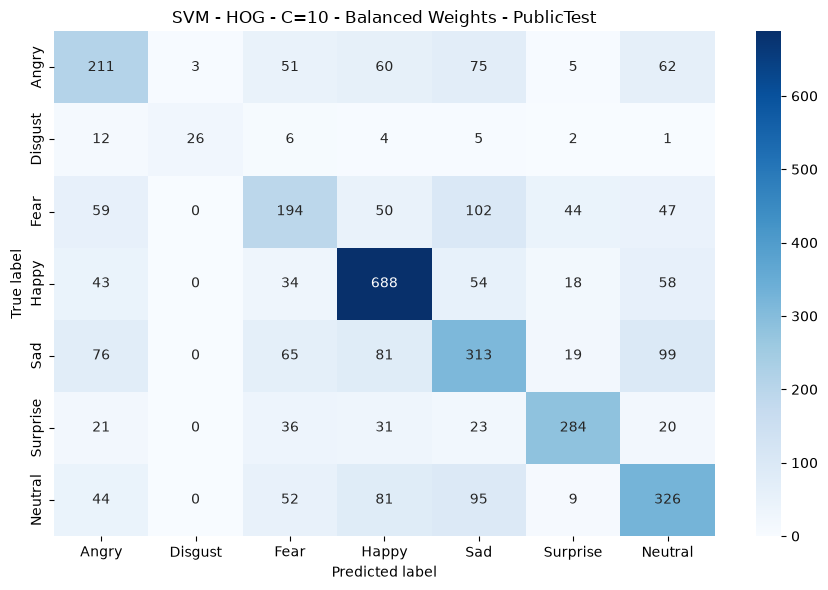

In [ ]:
# Confusion matrix for the balanced-weight SVM on the validation set
cm_balanced = confusion_matrix(y_valid, y_pred_hog_balanced, labels=range(7))

plt.figure(figsize=(9, 6))
sns.heatmap(cm_balanced, annot=True, fmt="d", cmap="Blues", xticklabels=emotion_names, yticklabels=emotion_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("SVM - HOG - C=10 - Balanced Weights - PublicTest")
plt.tight_layout()
# Save the figure as a high-resolution image
plt.savefig("fer_svm_hog_balanced_val.png", dpi=300, bbox_inches="tight")
plt.show()

### Class-Weight Results

Balanced weights did not improve the validation scores in this experiment. Accuracy changed from 56.98% to 56.90%, balanced accuracy from 54.05% to 53.95%, and macro F1 from 0.5624 to 0.5614. The differences are small. We keep the model without class weights for the next comparison.

## 7. Improvement 2: HOG + Landmarks

HOG describes local edges, while landmarks describe face shape. We join the two feature sets to test whether using both helps. Each image now has 1,036 features: 900 HOG features and 136 landmark features. Both feature sets use the same image order.

We keep `C=10`, `gamma="scale"`, and no class weights. Adding features also changes the value calculated by `gamma="scale"`, so this comparison reflects the full combined-feature setup.

In [ ]:
# Keep the same image order for both feature types
X_train_combined = np.hstack([X_train_hog, feats])
X_valid_combined = np.hstack([X_valid_hog, X_valid])

print("Training:", X_train_combined.shape)
print("Validation:", X_valid_combined.shape)

# Scale the combined features and train an SVM with the tuned C
svm_combined = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=best_c, gamma="scale", cache_size=512))

print("Training HOG + landmarks SVM...", flush=True)
svm_combined.fit(X_train_combined, trai_df["emotion"].values)
y_pred_combined = svm_combined.predict(X_valid_combined)

# Compare HOG alone with HOG + landmarks on the validation set
comparison = pd.DataFrame([
    {
        "Features": "HOG",
        "Accuracy": accuracy_score(y_valid, y_pred_svm_hog_tuned),
        "Balanced accuracy": balanced_accuracy_score(y_valid, y_pred_svm_hog_tuned),
        "Macro F1": f1_score(y_valid, y_pred_svm_hog_tuned, average="macro")
    },
    {
        "Features": "HOG + landmarks",
        "Accuracy": accuracy_score(y_valid, y_pred_combined),
        "Balanced accuracy": balanced_accuracy_score(y_valid, y_pred_combined),
        "Macro F1": f1_score(y_valid, y_pred_combined, average="macro")
    }
])

display(comparison.round(4))

# Save the combined-feature model
joblib.dump(svm_combined, "./models/svm_fer_model_hog_landmarks.pkl")

Training: (28709, 1036)
Validation: (3589, 1036)
Training HOG + landmarks SVM...


,Features,Accuracy,Balanced accuracy,Macro F1
0,HOG,0.5698,0.5405,0.5624
1,HOG + landmarks,0.5885,0.5594,0.5801


['./models/svm_fer_model_hog_landmarks.pkl']

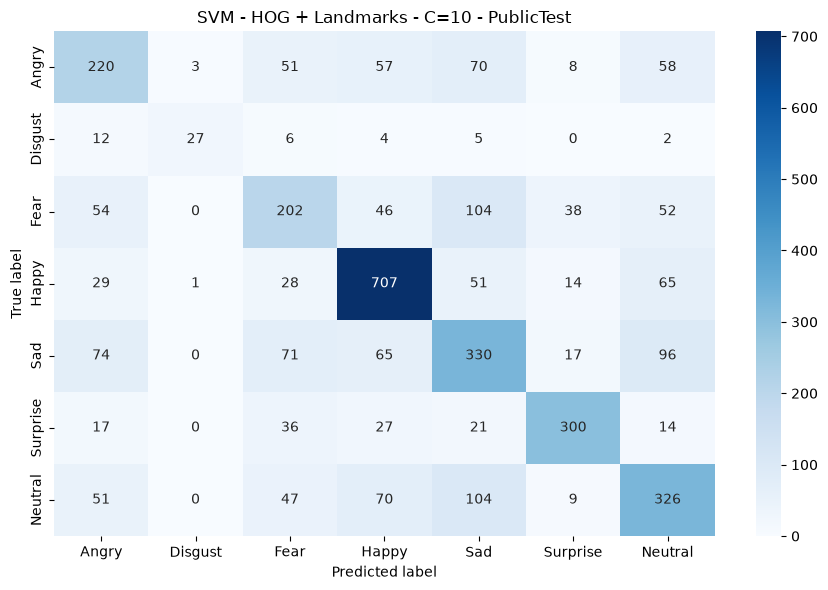

In [ ]:
# Confusion matrix for the HOG + landmarks SVM on the validation set
cm_combined = confusion_matrix(y_valid, y_pred_combined, labels=range(7))

plt.figure(figsize=(9, 6))
sns.heatmap(cm_combined, annot=True, fmt="d", cmap="Blues", xticklabels=emotion_names, yticklabels=emotion_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("SVM - HOG + Landmarks - C=10 - PublicTest")
plt.tight_layout()
# Save the figure as a high-resolution image
plt.savefig("fer_svm_combined_val.png", dpi=300, bbox_inches="tight")
plt.show()

### Combined-Feature Results and Model Choice

Combining HOG and landmarks improved all three validation scores. Accuracy rose from 56.98% to 58.85%, balanced accuracy from 54.05% to 55.94%, and macro F1 from 0.5624 to 0.5801.

This suggests that face shape adds useful information to HOG in this setup. Based on validation macro F1, we select the combined-feature SVM with `C=10` and no class weights.

## 8. Final PrivateTest Evaluation

We fix the model settings before evaluating PrivateTest. We use the same HOG and landmark functions and the fitted model pipeline. This step makes predictions only; it does not train the model again. We do not use the test scores to choose new settings.

Test features: (3589, 1036)
Final FER PrivateTest results
Accuracy: 0.5929
Balanced accuracy: 0.5678
Macro F1: 0.5887


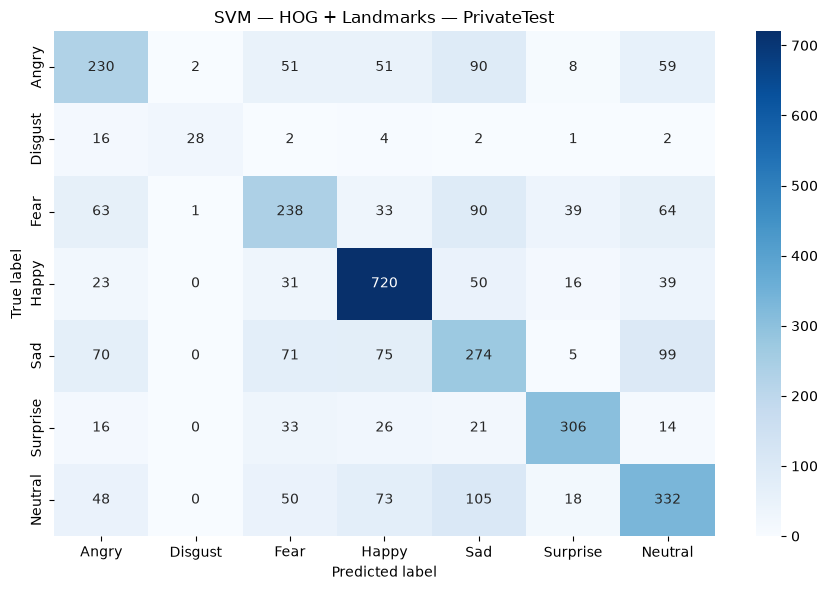

In [ ]:
# Load the FER2013 PrivateTest split
fer_test_df = pd.read_csv("./data/fer2013_test.csv")
y_test_fer = fer_test_df["emotion"].values

# Use the same feature functions as in training
X_test_hog = extract_hog_features(fer_test_df)
X_test_landmarks, _ = preprocessingFer(fer_test_df)
X_test_combined = np.hstack([X_test_hog, X_test_landmarks])

print("Test features:", X_test_combined.shape)

# Predict with the final HOG + landmarks SVM
y_pred_test_fer = svm_combined.predict(X_test_combined)

# Evaluate on the PrivateTest set
print("Final FER PrivateTest results")
print(f"Accuracy: {accuracy_score(y_test_fer, y_pred_test_fer):.4f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test_fer, y_pred_test_fer):.4f}")
print(f"Macro F1: {f1_score(y_test_fer, y_pred_test_fer, average='macro'):.4f}")

cm_test = confusion_matrix(y_test_fer, y_pred_test_fer, labels=range(7))

plt.figure(figsize=(9, 6))
sns.heatmap(cm_test, annot=True, fmt="d", cmap="Blues", xticklabels=emotion_names, yticklabels=emotion_names)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("SVM — HOG + Landmarks — PrivateTest")
plt.tight_layout()
plt.show()

### Final Results

| Split | Accuracy | Balanced accuracy | Macro F1 |
|---|---:|---:|---:|
| Validation | 0.5885 | 0.5594 | 0.5801 |
| PrivateTest | 0.5929 | 0.5678 | 0.5887 |

The final model reaches 59.29% test accuracy. The test scores are close to the validation scores, with no clear drop on this test split. The model still makes errors, so this result does not show that it will work equally well on another dataset or webcam images.

## 9. Save Results and the Final Model

We save the validation comparisons, test scores, and test confusion matrix as CSV files in `results`. The final scaler and SVM are saved together as `models/svm_fer_final.pkl`. To use this model, images must first go through the same HOG and landmark feature functions, with HOG placed before landmarks.

In [ ]:
from pathlib import Path

# create the output folder if it does not exist yet
output_dir = Path("./results")
output_dir.mkdir(exist_ok=True)

# save the validation results of each experiment
results_df.to_csv(output_dir / "fer_baseline_validation.csv", index=False)
svm_tuning_df.to_csv(output_dir / "fer_svm_c_validation.csv", index=False)
balanced_comparison.to_csv(output_dir / "fer_class_weights_validation.csv", index=False)
comparison.to_csv(output_dir / "fer_feature_combination_validation.csv", index=False)

# save the final test metrics of the chosen model
pd.DataFrame([{
    "Model": "SVM HOG + landmarks",
    "Split": "PrivateTest",
    "Accuracy": accuracy_score(y_test_fer, y_pred_test_fer),
    "Balanced accuracy": balanced_accuracy_score(y_test_fer, y_pred_test_fer),
    "Macro F1": f1_score(y_test_fer, y_pred_test_fer, average="macro")
}]).to_csv(output_dir / "fer_final_test.csv", index=False)

# save the confusion matrix on the test set
pd.DataFrame(cm_test, index=emotion_names, columns=emotion_names).to_csv(output_dir / "fer_final_test_confusion.csv")

# save the trained final model
joblib.dump(svm_combined, "./models/svm_fer_final.pkl")

print("FER results and final model saved.")

FER results and final model saved.


## 10. Overall Results Summary

The table below brings together all FER2013 validation results.
All models use the same validation set. We use validation macro F1
to select the final model.

| Features | Model / Setting | Accuracy | Balanced accuracy | Macro F1 |
|---|---|---:|---:|---:|
| Landmarks | Logistic Regression | 0.4319 | 0.3572 | 0.3513 |
| Landmarks | Random Forest | 0.4494 | 0.3759 | 0.3793 |
| Landmarks | SVM | 0.4648 | 0.3737 | 0.3670 |
| HOG | Logistic Regression | 0.4347 | 0.3948 | 0.3937 |
| HOG | Random Forest | 0.4528 | 0.3758 | 0.3885 |
| HOG | SVM, C = 0.1 | 0.4547 | 0.3552 | 0.3523 |
| HOG | SVM, C = 1 (baseline) | 0.5419 | 0.4819 | 0.5047 |
| HOG | SVM, C = 10 | 0.5698 | 0.5405 | 0.5624 |
| HOG | SVM, C = 10, balanced class weights | 0.5690 | 0.5395 | 0.5614 |
| PCA (150 components) | Logistic Regression | 0.3870 | 0.3040 | 0.2919 |
| PCA (150 components) | Random Forest | 0.3731 | 0.2907 | 0.2892 |
| PCA (150 components) | SVM | 0.4670 | 0.4020 | 0.4215 |
| **HOG + landmarks** | **SVM, C = 10** | **0.5885** | **0.5594** | **0.5801** |

### What the results show

HOG + SVM gives the best results among the nine baseline combinations.
PCA features give lower accuracy than HOG for all three classifiers.
Here, PCA is applied to raw pixels, so this is a comparison of feature
types, not a before-and-after PCA test on HOG.

Increasing C from 1 to 10 improves HOG SVM accuracy from 54.19% to
56.98%. Balanced class weights do not improve the overall scores
in this experiment.

Combining HOG and landmarks gives the best validation results.
Accuracy increases to 58.85%, and macro F1 increases to 0.5801.
Although landmarks alone perform worse than HOG, they add useful
information when combined with HOG in this setup.

### Final test result

We select the combined-feature SVM using validation macro F1,
then evaluate it on PrivateTest without changing its settings.

| Selected model | Test accuracy | Test balanced accuracy | Test macro F1 |
|---|---:|---:|---:|
| SVM, HOG + landmarks, C = 10 | 0.5929 | 0.5678 | 0.5887 |

The test scores are close to the validation scores. However,
performance on another dataset or live webcam images may differ.

## 11. Per-Emotion Results and Common Errors

We report precision, recall, F1, and the number of test
images for each emotion using the final model on PrivateTest.
We also list the ten most common incorrect predictions
to identify which emotions are often confused.

In [ ]:
from sklearn.metrics import classification_report
import numpy as np
import pandas as pd

emotion_names = ["Angry", "Disgust", "Fear", "Happy", "Sad", "Surprise", "Neutral"]

# Show precision, recall, and F1 for each emotion
report = classification_report(y_test_fer, y_pred_test_fer, labels=np.arange(7), target_names=emotion_names, output_dict=True, zero_division=0)

class_results = pd.DataFrame(report).T.loc[emotion_names]
display(class_results.round(4))

# Show the most common incorrect predictions
# Zero out the diagonal so only wrong predictions remain
error_matrix = cm_test.copy()
np.fill_diagonal(error_matrix, 0)

confusion_rows = []

# Collect every (true, predicted) pair that has at least one error
for true_label in range(7):
    for predicted_label in range(7):
        count = int(error_matrix[true_label, predicted_label])

        if count > 0:
            confusion_rows.append({
                "True emotion": emotion_names[true_label],
                "Predicted emotion": emotion_names[predicted_label],
                "Number of images": count
            })

# Sort by error count and show the top 10
common_errors = pd.DataFrame(confusion_rows).sort_values("Number of images", ascending=False)

display(common_errors.head(10))

,precision,recall,f1-score,support
Angry,0.4936,0.4684,0.4807,491.0
Disgust,0.9032,0.5091,0.6512,55.0
Fear,0.5000,0.4508,0.4741,528.0
Happy,0.7332,0.8191,0.7738,879.0
Sad,0.4335,0.4613,0.4470,594.0
Surprise,0.7786,0.7356,0.7565,416.0
Neutral,0.5452,0.5304,0.5377,626.0


,True emotion,Predicted emotion,Number of images
36,Neutral,Sad,105
27,Sad,Neutral,99
3,Angry,Sad,90
15,Fear,Sad,90
25,Sad,Happy,75
35,Neutral,Happy,73
24,Sad,Fear,71
23,Sad,Angry,70
17,Fear,Neutral,64
12,Fear,Angry,63


## 12. Examples of Misclassified Images

For each emotion, we show up to three images that were misclassified in the PrivateTest dataset and list their ground-truth labels and predicted labels.
By setting a fixed random seed, we ensure that the selection process for these samples is reproducible.

These examples help us analyze the challenges the model faces, such as shadows, head pose, occlusion, and similar facial expressions. They provide clues as to the causes of errors but do not directly prove their exact causes.


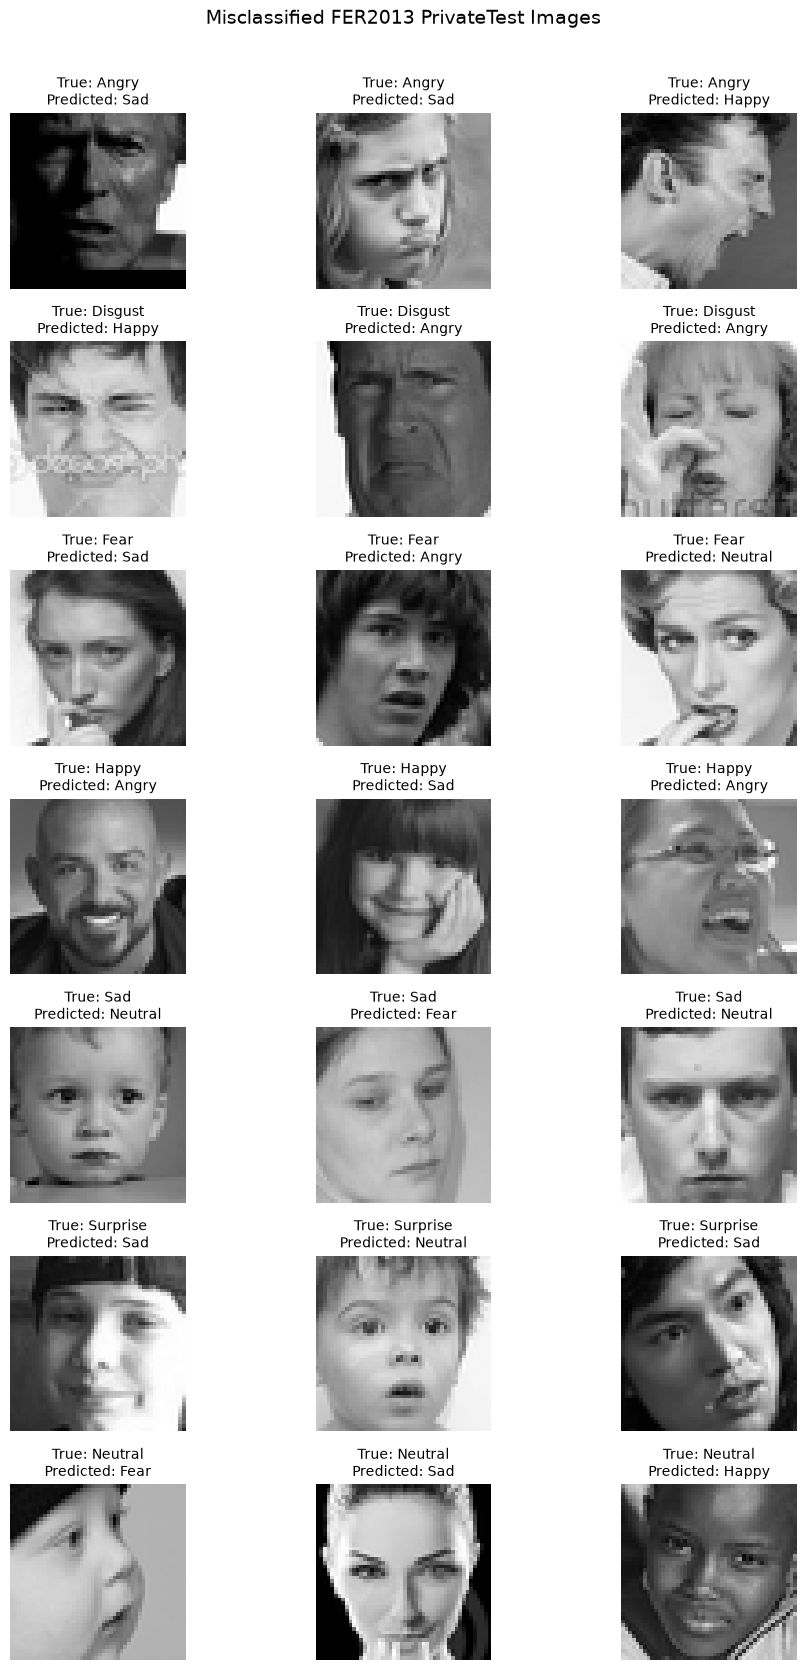

In [ ]:
import matplotlib.pyplot as plt

# fix the random seed so the same images are picked every run
rng = np.random.default_rng(42)

true_labels = np.asarray(y_test_fer)
predicted_labels = np.asarray(y_pred_test_fer)

# 7 rows for 7 emotion classes, 3 images per row
fig, axes = plt.subplots(7, 3, figsize=(10, 17))

for label in range(7):
    # find samples whose true class is `label` but were predicted wrong
    wrong_indices = np.flatnonzero((true_labels == label) & (predicted_labels != label))
    # randomly pick up to 3 of them
    selected_indices = rng.choice(wrong_indices, size=min(3, len(wrong_indices)), replace=False)
    for column in range(3):
        ax = axes[label, column]
        ax.axis("off")
        if column < len(selected_indices):
            index = selected_indices[column]
            # convert the pixel string into a 48x48 image
            image = np.fromstring(fer_test_df.iloc[index]["pixels"], sep=" ", dtype=np.float32).reshape(48, 48)
            predicted_name = emotion_names[int(predicted_labels[index])]
            ax.imshow(image, cmap="gray", vmin=0, vmax=255)
            ax.set_title(f"True: {emotion_names[label]}\nPredicted: {predicted_name}", fontsize=10)
        elif column == 0:
            # no errors for this class, so put a note in the first cell
            ax.set_title(f"{emotion_names[label]}: no errors", fontsize=10)

plt.suptitle("Misclassified FER2013 PrivateTest Images", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

## 13. Export Confusion Matrices

We save confusion matrices for the nine baseline models
and four improvement configurations on PublicTest,
together with the final selected model on PrivateTest.

Rows show true labels, and columns show predicted labels.
The figures are saved as 300 dpi PNG files in `figures_cm`
for the report appendix, using the fitted models without
retraining them.

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Folder for all confusion matrix figures
out_dir = Path("./figures_cm")
out_dir.mkdir(exist_ok=True)

emotion_names = ["Angry", "Disgust", "Fear", "Happy", "Sad", "Surprise", "Neutral"]

# Plot one confusion matrix and save it as a PNG file
def save_cm(y_true, y_pred, title, filename):
    cm = confusion_matrix(y_true, y_pred, labels=range(7))
    plt.figure(figsize=(9, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=emotion_names, yticklabels=emotion_names)
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(title)
    plt.tight_layout()
    plt.savefig(out_dir / filename, dpi=300, bbox_inches="tight")
    plt.close()
    print("saved", filename)

# 1. Nine baselines (PublicTest)
# Each entry: feature type, classifier name, fitted model, validation features, output file name
baseline = [
    ("Landmarks", "LR",  lr,      X_valid,     "fer_lm_lr_val.png"),
    ("Landmarks", "RF",  rf,      X_valid,     "fer_lm_rf_val.png"),
    ("Landmarks", "SVM", svm,     X_valid,     "fer_lm_svm_val.png"),
    ("HOG",       "LR",  lr_hog,  X_valid_hog, "fer_hog_lr_val.png"),
    ("HOG",       "RF",  rf_hog,  X_valid_hog, "fer_hog_rf_val.png"),
    ("HOG",       "SVM", svm_hog, X_valid_hog, "fer_hog_svm_c1_val.png"),
    ("PCA",       "LR",  lr_pca,  X_valid_pca, "fer_pca_lr_val.png"),
    ("PCA",       "RF",  rf_pca,  X_valid_pca, "fer_pca_rf_val.png"),
    ("PCA",       "SVM", svm_pca, X_valid_pca, "fer_pca_svm_val.png"),
]
for feat, clf, model, X, fname in baseline:
    save_cm(y_valid, model.predict(X), f"{clf} — {feat} — PublicTest", fname)

# 2. Improvement experiments (PublicTest)
save_cm(y_valid, svm_hog_candidates[0.1].predict(X_valid_hog), "SVM — HOG — C=0.1 — PublicTest", "fer_hog_svm_c0.1_val.png")
save_cm(y_valid, svm_hog_candidates[10.0].predict(X_valid_hog), "SVM — HOG — C=10 — PublicTest", "fer_hog_svm_c10_val.png")
save_cm(y_valid, svm_hog_balanced.predict(X_valid_hog), "SVM — HOG — C=10 — Balanced weights — PublicTest", "fer_hog_svm_c10_balanced_val.png")
save_cm(y_valid, svm_combined.predict(X_valid_combined), "SVM — HOG + Landmarks — C=10 — PublicTest", "fer_hog_lm_svm_c10_val.png")

# 3. Final model (PrivateTest)
save_cm(y_test_fer, y_pred_test_fer, "SVM — HOG + Landmarks — C=10 — PrivateTest", "fer_final_hog_lm_svm_c10_test.png")

# Count the saved figures
print(f"\nDone. {len(list(out_dir.glob('*.png')))} files in {out_dir.resolve()}")

saved fer_lm_lr_val.png
saved fer_lm_rf_val.png
saved fer_lm_svm_val.png
saved fer_hog_lr_val.png
saved fer_hog_rf_val.png
saved fer_hog_svm_c1_val.png
saved fer_pca_lr_val.png
saved fer_pca_rf_val.png
saved fer_pca_svm_val.png
saved fer_hog_svm_c0.1_val.png
saved fer_hog_svm_c10_val.png
saved fer_hog_svm_c10_balanced_val.png
saved fer_hog_lm_svm_c10_val.png
saved fer_final_hog_lm_svm_c10_test.png

Done. 14 files in C:\Users\20231809\Desktop\study\master\Y1\Q1\Data Analysis\assignment2\Assignment2_2026\figures_cm
